In [1]:
#import scientific libraries


In [2]:
import numpy as np
import matplotlib.pyplot as plt

print("MethaneScope AI")
print("Lesson 1.4: Satellite Resolution")

MethaneScope AI
Lesson 1.4: Satellite Resolution


In [3]:
#Generate two absorption features

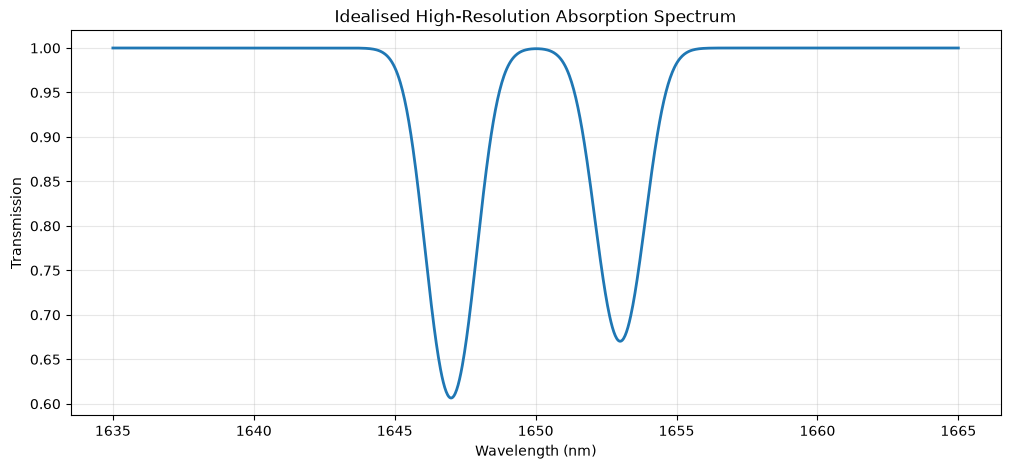

In [4]:
# Wavelength range
wavelengths = np.linspace(1635, 1665, 1201)

# Simulated optical-depth features
feature_1 = 0.5 * np.exp(
    -0.5 * ((wavelengths - 1647) / 0.8) ** 2
)

feature_2 = 0.4 * np.exp(
    -0.5 * ((wavelengths - 1653) / 0.8) ** 2
)

# Combine both absorption features
optical_depth = feature_1 + feature_2

# Simplified Beer-Lambert transmission
ideal_spectrum = np.exp(-optical_depth)

plt.figure(figsize=(12, 5))

plt.plot(
    wavelengths,
    ideal_spectrum,
    linewidth=2
)

plt.xlabel("Wavelength (nm)")
plt.ylabel("Transmission")
plt.title("Idealised High-Resolution Absorption Spectrum")
plt.grid(alpha=0.3)

plt.show()

In [5]:
#Simulate instruments with different spectral resolutions


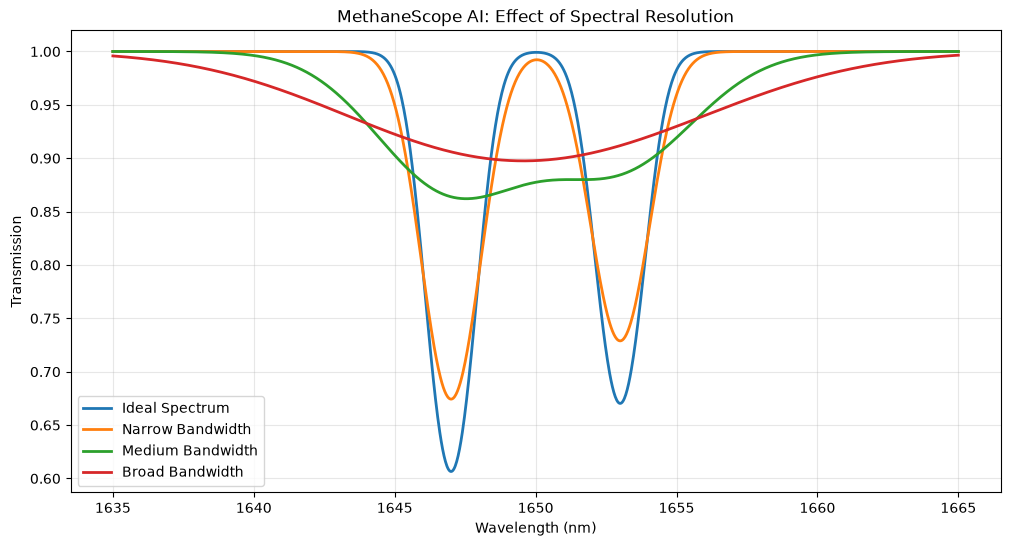

In [6]:
def simulate_sensor(spectrum, wavelengths, sigma_nm):
    """
    Simulate a Gaussian instrument spectral response.

    sigma_nm: response standard deviation in nm
    """
    wavelength_step = wavelengths[1] - wavelengths[0]

    sigma_pixels = sigma_nm / wavelength_step

    radius = int(np.ceil(4 * sigma_pixels))

    x = np.arange(-radius, radius + 1)

    kernel = np.exp(
        -0.5 * (x / sigma_pixels) ** 2
    )

    kernel = kernel / kernel.sum()

    padded = np.pad(
        spectrum,
        (radius, radius),
        mode="edge"
    )

    return np.convolve(
        padded,
        kernel,
        mode="valid"
    )


# Instrument response widths
sensor_narrow = simulate_sensor(
    ideal_spectrum, wavelengths, 0.6
)

sensor_medium = simulate_sensor(
    ideal_spectrum, wavelengths, 2.5
)

sensor_broad = simulate_sensor(
    ideal_spectrum, wavelengths, 5.0
)

plt.figure(figsize=(12, 6))

plt.plot(
    wavelengths, ideal_spectrum,
    label="Ideal Spectrum", linewidth=2
)

plt.plot(
    wavelengths, sensor_narrow,
    label="Narrow Bandwidth", linewidth=2
)

plt.plot(
    wavelengths, sensor_medium,
    label="Medium Bandwidth", linewidth=2
)

plt.plot(
    wavelengths, sensor_broad,
    label="Broad Bandwidth", linewidth=2
)

plt.xlabel("Wavelength (nm)")
plt.ylabel("Transmission")

plt.title(
    "MethaneScope AI: Effect of Spectral Resolution"
)

plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [7]:
#Simulate methane enhancement


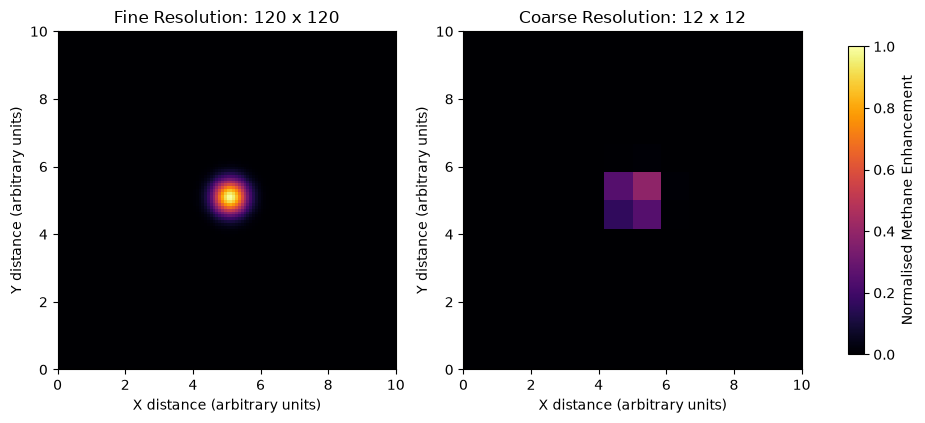

Fine-grid peak: 0.994
Coarse-grid peak: 0.387


In [8]:
# Construct a simulated geographical grid
size = 120

x = np.linspace(0, 10, size)
y = np.linspace(0, 10, size)

X, Y = np.meshgrid(x, y)

# Synthetic methane enhancement centred near (5, 5)
plume = np.exp(
    -(
        (X - 5.1) ** 2 +
        (Y - 5.1) ** 2
    ) / (2 * 0.35 ** 2)
)

# Average blocks of fine pixels into larger pixels
coarse_plume = plume.reshape(
    12, 10, 12, 10
).mean(axis=(1, 3))

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 5)
)

axes[0].imshow(
    plume,
    cmap="inferno",
    origin="lower",
    extent=[0, 10, 0, 10],
    vmin=0,
    vmax=1,
    interpolation="nearest"
)

axes[0].set_title("Fine Resolution: 120 x 120")

im = axes[1].imshow(
    coarse_plume,
    cmap="inferno",
    origin="lower",
    extent=[0, 10, 0, 10],
    vmin=0,
    vmax=1,
    interpolation="nearest"
)

axes[1].set_title("Coarse Resolution: 12 x 12")

for ax in axes:
    ax.set_xlabel("X distance (arbitrary units)")
    ax.set_ylabel("Y distance (arbitrary units)")

fig.colorbar(
    im,
    ax=axes,
    label="Normalised Methane Enhancement",
    shrink=0.8
)

plt.show()

print("Fine-grid peak:", round(plume.max(), 3))
print("Coarse-grid peak:", round(coarse_plume.max(), 3))